# Taller integrador -- Deep Learning aplicado a mercados financieros
# Diplomado en Data Science and Machine Learning Applied to Financial Markets
# ITAM Extension Universitaria y Desarrollo Ejecutivo

### De funciones de activacion a un portafolio de criptomonedas completo, con datos reales

> **Al terminar este taller sabras:**
> - Repasar y aplicar funciones de activacion, backpropagation, optimizadores y regularizacion.
> - Construir una red feedforward para predecir el movimiento de un activo con features hechos a mano.
> - Construir una CNN 1D y comparar RNN, LSTM y GRU sobre la misma tarea de prediccion.
> - Usar autoencoders para imputar datos faltantes y para "limpiar" una matriz de covarianza.
> - Construir un portafolio de inversion con la teoria de Markowitz sobre una covarianza denoised.
> - Calcular medidas de riesgo (VaR historico y parametrico) y entender el concepto de CVA via
>   simulacion Monte Carlo.
> - Elegir, para un escenario financiero nuevo, que arquitectura de red conviene usar y por que.

### Como usar este notebook

1. **Ejecuten las celdas en orden** (Shift + Enter).
2. Cada parte tiene una **explicacion**, un **desarrollo guiado con datos reales**, y **retos** que
   ustedes completan en una celda en blanco.
3. Cuando vean una celda marcada **RETO**, van a escribir codigo nuevo -- se las voy a pedir en voz
   alta para que las resolvamos juntos.
4. Cuando vean una celda marcada **PREGUNTA**, es para discutir en grupo -- no hay que escribir codigo.
5. Duracion total: **3 horas**.

### El dataset que usamos en todo el taller

Precios diarios **reales** de 6 criptomonedas (Bitcoin, Ethereum, Solana, Dogecoin, Cardano y Ripple),
tomados del exchange Binance. Cubren el mismo periodo (mas de 500 dias de cotizacion, sin huecos) para
las 6 monedas, y llegan practicamente hasta hoy -- estos no son datos de hace 10 años, son datos que
siguen actualizandose.

**Aviso importante:** todo lo que hacemos hoy con este dataset es un ejercicio educativo sobre redes
neuronales y optimizacion de portafolios. Las criptomonedas son activos con volatilidad extrema. Nada
de lo que vean hoy es una recomendacion de inversion, ni una prediccion confiable de precios futuros.

### Mapa del taller

| Parte | Tema | Conecta con el temario |
|---|---|---|
| 0 | Preparacion y primer vistazo a los datos | -- |
| 1 | Repaso relampago: activacion, feedforward, optimizadores, regularizacion | Modulo Deep Learning, temas 1-4 |
| 2 | Red feedforward: features hechos a mano | Modulo Deep Learning, tema 2 + Aplicaciones |
| 3 | CNN 1D sobre ventanas de rendimientos | Modulo Deep Learning, tema 5 (CNN) |
| 4 | RNN, LSTM y GRU sobre las mismas ventanas | Modulo Deep Learning, tema 7 (RNN/LSTM/GRU) |
| 5 | Autoencoders: imputacion de datos y limpieza de covarianza | Modulo Deep Learning, tema 6 |
| 6 | Portafolios de inversion: Markowitz sobre covarianza denoised | Aplicaciones: rendimientos esperados, portafolios |
| 7 | Medicion de riesgo: VaR y una mirada a CVA | Aplicaciones: VaR, simulacion Montecarlo, CVA |
| 8 | Capstone: elegir la arquitectura correcta | Integra todo el temario del modulo |
| 9 | Cierre integrador | -- |


---
## Parte 0 -- Preparacion 

Cargamos las librerias y los datos reales que vamos a usar en todo el taller.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import stats

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, classification_report

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

GREEN, DARKGREEN, GOLD, BROWN, GRAY, BLUE, RED = \
    "#006851", "#306E49", "#AD6B0C", "#602507", "#444444", "#2E5FA3", "#B03A2E"
COLORES_MONEDA = {"BTC": GOLD, "ETH": BLUE, "SOL": GREEN, "DOGE": BROWN, "ADA": DARKGREEN, "XRP": GRAY}

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.edgecolor"] = "#DADADA"
plt.rcParams["font.size"] = 10

print("Listo.")

Listo.


In [2]:
df = pd.read_csv("data/crypto_precios_panel.csv", parse_dates=["date"])
close = df.pivot(index="date", columns="symbol", values="close").sort_index()
rendimientos = close.pct_change().dropna()
tickers = list(close.columns)
n_activos = len(tickers)

print(f"Criptomonedas: {n_activos} -> {tickers}")
print(f"Rango de fechas: {close.index.min().date()} a {close.index.max().date()}")
print(f"Dias de cotizacion (comunes a las {n_activos} monedas): {len(close)}")
close.head()

Criptomonedas: 6 -> ['ADA', 'BTC', 'DOGE', 'ETH', 'SOL', 'XRP']
Rango de fechas: 2025-03-01 a 2026-08-23
Dias de cotizacion (comunes a las 6 monedas): 514


symbol,ADA,BTC,DOGE,ETH,SOL,XRP
date,,,,,,
2025-03-01,0.6593,86064.53,0.20673,2217.39,143.66,2.1916
2025-03-02,1.1350,94270.00,0.23931,2518.11,178.71,2.9396
2025-03-03,0.8578,86220.61,0.19913,2149.01,142.16,2.3873
2025-03-04,0.9409,87281.98,0.19905,2171.51,144.79,2.4543
2025-03-05,0.9741,90606.01,0.20471,2241.59,146.28,2.4998


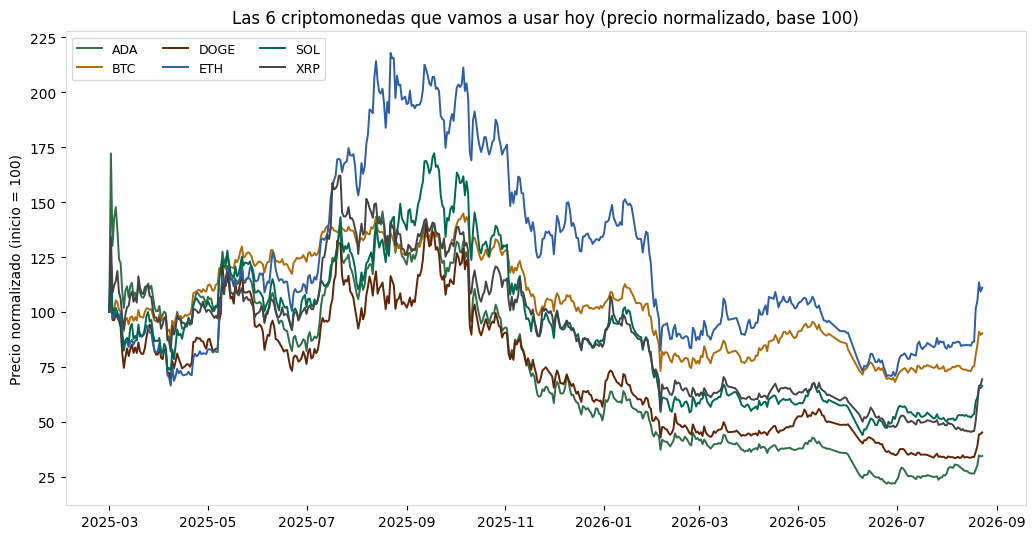

Rendimiento total en todo el periodo, de mayor a menor:
  ETH   +11.1%
  BTC   -9.7%
  XRP   -30.6%
  SOL   -33.6%
  DOGE  -54.8%
  ADA   -65.6%


In [3]:
normalizado = close / close.iloc[0] * 100
retorno_total = (close.iloc[-1] / close.iloc[0] - 1).sort_values(ascending=False)

plt.figure(figsize=(10.5, 5.5))
for ticker in tickers:
    plt.plot(normalizado.index, normalizado[ticker], label=ticker,
              color=COLORES_MONEDA.get(ticker), linewidth=1.4)
plt.title("Las 6 criptomonedas que vamos a usar hoy (precio normalizado, base 100)")
plt.ylabel("Precio normalizado (inicio = 100)")
plt.legend(ncol=3, fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

print("Rendimiento total en todo el periodo, de mayor a menor:")
for t, r in retorno_total.items():
    print(f"  {t:5s} {r:+.1%}")



```
Datos reales (6 criptomonedas, mismo periodo)
        |
        v
Parte 1: repaso de activacion, feedforward, optimizadores, regularizacion
        |
        v
Parte 2: red feedforward       -->  features hechos a mano (ret1, ma10, ma50, ...)
Parte 3: CNN 1D                -->  aprende sus propios filtros sobre ventanas de rendimientos
Parte 4: RNN / LSTM / GRU      -->  las mismas ventanas, procesadas de forma secuencial
        |
        v
Parte 5: autoencoders  -->  imputar datos faltantes  +  limpiar la matriz de covarianza
        |
        v
Parte 6: portafolio de inversion (Markowitz) sobre la covarianza limpia
        |
        v
Parte 7: medicion de riesgo del portafolio (VaR, Monte Carlo / CVA)
        |
        v
Parte 8: capstone -- para escenarios financieros nuevos, ¿que arquitectura usarian?
```

Cada parte usa el resultado de la anterior, o compite contra ella con la misma tarea -- es un solo
pipeline, no ocho ejercicios sueltos.

---
## Parte 1 -- Repaso 

Antes de construir el pipeline completo, repasamos rapido los bloques que ya vimos en sesiones
anteriores, porque los vamos a usar todos hoy.

### Funciones de activacion

Recordatorio: una neurona calcula una combinacion lineal de sus entradas (`w . x + b`) y despues le
aplica una funcion de activacion no lineal. Sin esa no linealidad, apilar muchas capas seria
matematicamente equivalente a una sola capa lineal.

Abajo ya esta implementada la sigmoide. Les toca completar tangente hiperbolica y ReLU.

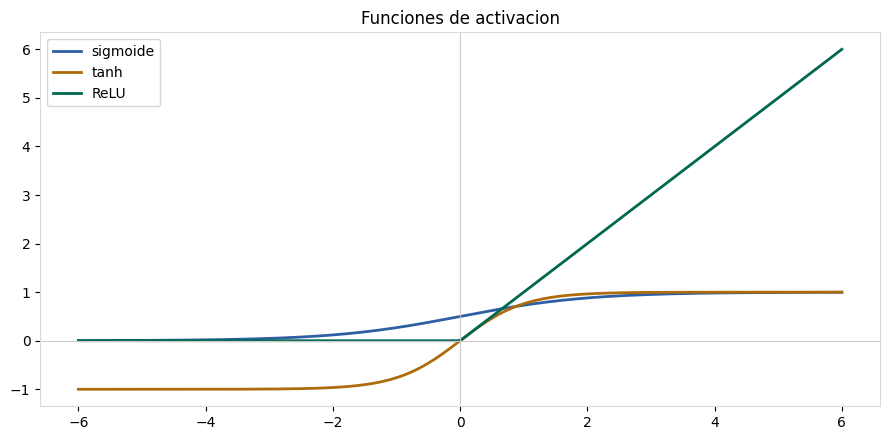

In [4]:
def sigmoide(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return (np.exp(x)-np.exp(-x))/(np.exp(x)+np.exp(-x))

def relu(x):
    return np.where(x>0, x, 0)

x = np.linspace(-6, 6, 200)

plt.figure(figsize=(9, 4.5))
plt.plot(x, sigmoide(x), label="sigmoide", color=BLUE, lw=2)
plt.plot(x, tanh(x), label="tanh", color=GOLD, lw=2)
plt.plot(x, relu(x), label="ReLU", color=GREEN, lw=2)
plt.axhline(0, color="#CCCCCC", lw=0.8)
plt.axvline(0, color="#CCCCCC", lw=0.8)
plt.legend()
plt.title("Funciones de activacion")
plt.tight_layout()
plt.show()

**PREGUNTA 1** -- ReLU es la activacion mas comun en capas ocultas de redes profundas, por encima
de sigmoide o tanh. ¿Por que? (pista: piensen en que pasa con el gradiente de sigmoide cuando `x` es
muy grande o muy chico, y comparen con el gradiente de ReLU para `x > 0`).

### El forward pass de una neurona, a mano

Antes de usar Keras, vale la pena calcular el forward pass de una sola neurona con numpy puro, para
que quede claro que no hay magia: es un producto punto, una suma, y una activacion.

In [5]:
# Una neurona con 4 entradas
x_ejemplo = np.array([0.5, -0.2, 1.3, 0.8])
w_ejemplo = np.array([0.4, 0.9, -0.6, 0.2])
b_ejemplo = 0.1

# RETO 2 -- completa el forward pass de esta neurona:
# 1. calcula la combinacion lineal z = w . x + b
z = np.dot(x_ejemplo,w_ejemplo) + b_ejemplo
# 2. aplica la funcion sigmoide a z para obtener la salida de la neurona
salida_neurona = sigmoide(z)

print(f"z = {z:.4f}")
print(f"salida de la neurona (activacion sigmoide) = {salida_neurona:.4f}")

z = -0.5000
salida de la neurona (activacion sigmoide) = 0.3775


### Optimizadores: por que no basta con "bajar la pendiente"

El gradiente descendente actualiza los pesos en la direccion que mas reduce la perdida. Vamos a verlo
correr, paso a paso, sobre una funcion muy simple: `f(w) = (w - 3)^2`, cuyo minimo sabemos que esta en
`w = 3`.

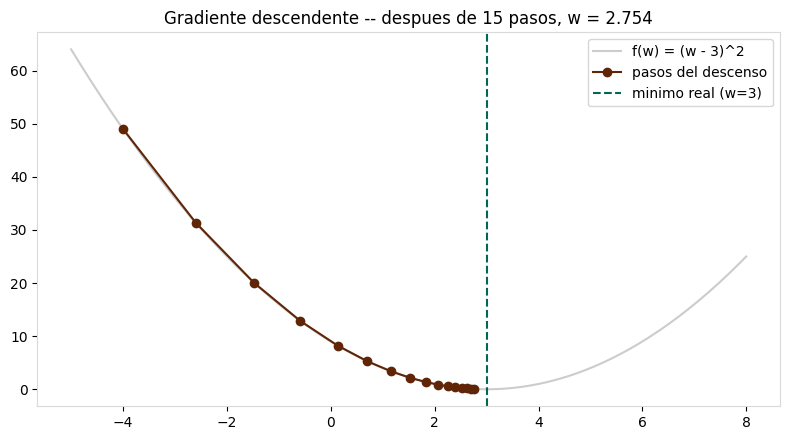

In [6]:
def f(w):
    return (w - 3) ** 2

def gradiente_f(w):
    return 2 * (w - 3)

w = -4.0          # punto de partida, lejos del minimo
lr = 0.1          # tasa de aprendizaje
historial = [w]

for paso in range(15):
    w = w - lr * gradiente_f(w)
    historial.append(w)

plt.figure(figsize=(8, 4.5))
ws = np.linspace(-5, 8, 200)
plt.plot(ws, f(ws), color="#CCCCCC", lw=1.5, label="f(w) = (w - 3)^2")
plt.plot(historial, [f(w) for w in historial], "o-", color=BROWN, label="pasos del descenso")
plt.axvline(3, color=GREEN, ls="--", label="minimo real (w=3)")
plt.legend()
plt.title(f"Gradiente descendente -- despues de 15 pasos, w = {historial[-1]:.3f}")
plt.tight_layout()
plt.show()

**RETO 3** -- En la celda de abajo, repitan el experimento con `lr = 0.9` y con `lr = 1.05`.
Escriban su codigo copiando el patron de la celda anterior (pueden copiar/pegar y solo cambiar `lr`
y el nombre de la variable `historial`). ¿Que le pasa a la convergencia en cada caso? Esto es
exactamente el problema que resuelven Momentum, Adam y los demas optimizadores que vimos: adaptar el
tamaño de paso automaticamente.

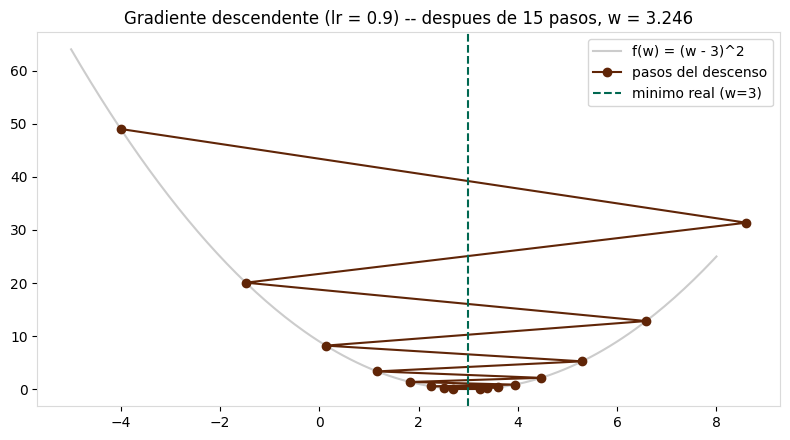

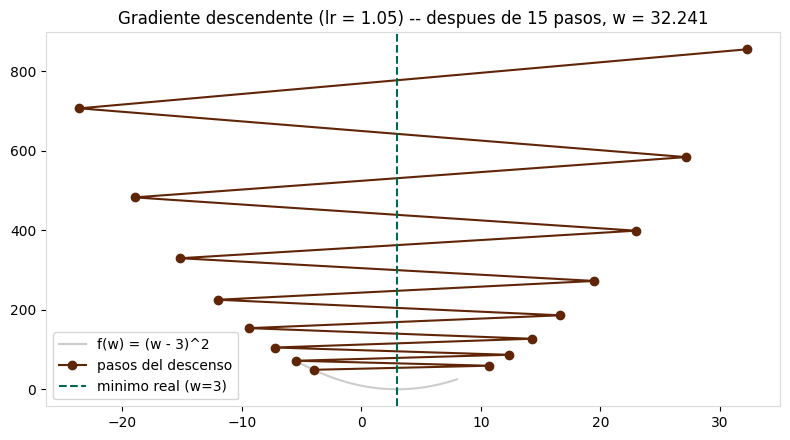

In [7]:
# RETO 3 -- espacio para su codigo (lr = 0.9 y lr = 1.05)
lr1 = 0.9 
lr2 = 1.05        

w = -4.0  
historial1 = [w]
for paso in range(15):
    w = w - lr1 * gradiente_f(w)
    historial1.append(w)

w = -4.0  
historial2 = [w]
for paso in range(15):
    w = w - lr2 * gradiente_f(w)
    historial2.append(w)

plt.figure(figsize=(8, 4.5))
ws = np.linspace(-5, 8, 200)
plt.plot(ws, f(ws), color="#CCCCCC", lw=1.5, label="f(w) = (w - 3)^2")
plt.plot(historial1, [f(w) for w in historial1], "o-", color=BROWN, label="pasos del descenso")
plt.axvline(3, color=GREEN, ls="--", label="minimo real (w=3)")
plt.legend()
plt.title(f"Gradiente descendente (lr = 0.9) -- despues de 15 pasos, w = {historial1[-1]:.3f}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
ws = np.linspace(-5, 8, 200)
plt.plot(ws, f(ws), color="#CCCCCC", lw=1.5, label="f(w) = (w - 3)^2")
plt.plot(historial2, [f(w) for w in historial2], "o-", color=BROWN, label="pasos del descenso")
plt.axvline(3, color=GREEN, ls="--", label="minimo real (w=3)")
plt.legend()
plt.title(f"Gradiente descendente (lr = 1.05) -- despues de 15 pasos, w = {historial2[-1]:.3f}")
plt.tight_layout()
plt.show()

RESPUESTA: Un learning rate fijo puede ser demasiado chico (lento) o demasiado grande (inestable/diverge)

### Regularizacion: por que un modelo demasiado flexible no es lo que queremos

Recordatorio de lo que ya vimos: L1, L2, Dropout y Batch Normalization existen para evitar que la red
memorice el ruido de los datos de entrenamiento en vez de aprender el patron real.

**PREGUNTA 2** -- Si un modelo tiene accuracy de 0.95 en entrenamiento pero solo 0.55 en prueba, ¿que
esta pasando? ¿Que tecnica de las que ya vimos ayudaria mas: Dropout, Early Stopping, o mas datos de
entrenamiento? Justifiquen.

- Es un caso de overfitting, el modelo memorizó patrones específicos (incluso ruido) de los datos de entrenamiento en vez de aprender patrones generales que se transfieran a datos nuevos. Dropout ayuda porque durante el entrenamiento apaga aleatoriamente un porcentaje de neuronas en cada paso, forzando a la red a no depender demasiado de neuronas específicas ni de combinaciones muy particulares. Empuja al modelo a aprender representaciones más robustas y distribuidas.

---
## Parte 2 -- Red feedforward

Vamos a construir una red feedforward que prediga si el precio de una criptomoneda va a subir en los
proximos 10 dias, usando indicadores que **nosotros** diseñamos a mano. En las partes 3 y 4 vamos a
resolver el mismo problema dejando que la red aprenda sus propias representaciones, y vamos a comparar
los tres enfoques con numeros reales.

### Ingenieria de features

Para cada moneda construimos, dia por dia, un conjunto de indicadores calculados **solo con
informacion disponible hasta ese dia** (nada del futuro):

- `ret1`: rendimiento diario
- `ma10`, `ma50`: distancia porcentual del precio a su media movil de 10 y 50 dias
- `vol21`: volatilidad (desviacion estandar de rendimientos) de los ultimos 21 dias
- `mom21`: momentum -- rendimiento acumulado de los ultimos 21 dias

La etiqueta (`label`) es 1 si el precio sube en los proximos 10 dias, 0 si no. Usamos el mismo
horizonte (`HORIZONTE = 10`) en toda la sesion para que las partes 2, 3 y 4 sean comparables.

In [11]:
HORIZONTE = 10

def construir_features(precios, horizonte=HORIZONTE):
    ret1 = precios.pct_change()
    ma10 = precios.rolling(10).mean() / precios - 1
    ma50 = precios.rolling(50).mean() / precios - 1
    vol21 = ret1.rolling(21).std()
    mom21 = precios.pct_change(21)
    retorno_futuro = precios.shift(-horizonte) / precios - 1
    label = (retorno_futuro > 0).astype(float)

    feats = pd.DataFrame({
        "ret1": ret1, "ma10": ma10, "ma50": ma50,
        "vol21": vol21, "mom21": mom21, "label": label,
    })
    return feats.dropna()

bloques = []
for ticker in tickers:
    f = construir_features(close[ticker])
    f["ticker"] = ticker
    f["date"] = f.index
    bloques.append(f)

datos = pd.concat(bloques, ignore_index=True)
print("Observaciones totales:", len(datos))
print("Proporcion de la clase 'sube':", round(datos["label"].mean(), 3))
datos.head()

Observaciones totales: 2790
Proporcion de la clase 'sube': 0.449


,ret1,ma10,ma50,vol21,mom21,label,ticker,date
0,0.001116,-0.003757,0.126288,0.048892,-0.066845,1.0,ADA,2025-04-19
1,-0.012735,0.010835,0.139555,0.048823,-0.062008,1.0,ADA,2025-04-20
2,0.006450,0.004406,0.115886,0.048854,-0.056815,1.0,ADA,2025-04-21
3,0.088433,-0.074271,0.019971,0.052459,0.003545,1.0,ADA,2025-04-22
4,0.026936,-0.090039,-0.013754,0.051098,0.090156,1.0,ADA,2025-04-23


**RETO 4** -- `construir_features` usa 5 indicadores. En la celda de abajo, escriban una funcion
`construir_features_extendida` que agregue un sexto indicador: un RSI simplificado (relative strength
index), definido como la razon entre el promedio de ganancias y el promedio de perdidas de los ultimos
14 dias. Formula simplificada:

```
ganancias = rendimiento donde rendimiento > 0, si no 0
perdidas  = -rendimiento donde rendimiento < 0, si no 0
rs   = media_movil_14(ganancias) / media_movil_14(perdidas)
rsi  = 100 - 100 / (1 + rs)
```

No hace falta que corran el pipeline completo con este nuevo feature -- el objetivo es que practiquen
construyendo un indicador nuevo con `rolling()`, igual que los que ya vieron arriba.

In [12]:
# RETO 4 -- espacio para su codigo (funcion construir_features_extendida)
HORIZONTE = 10

def construir_features_extendida(precios, horizonte=HORIZONTE):
    ret1 = precios.pct_change()
    ma10 = precios.rolling(10).mean() / precios - 1
    ma50 = precios.rolling(50).mean() / precios - 1
    vol21 = ret1.rolling(21).std()
    mom21 = precios.pct_change(21)

    ganancias = ret1.where(ret1 > 0, 0)
    perdidas = -ret1.where(ret1 < 0, 0)
    rs = ganancias.rolling(14).mean() / perdidas.rolling(14).mean()
    rsi = 100 - 100 / (1 + rs)

    retorno_futuro = precios.shift(-horizonte) / precios - 1
    label = (retorno_futuro > 0).astype(float)

    feats = pd.DataFrame({
        "ret1": ret1, "ma10": ma10, "ma50": ma50,
        "vol21": vol21, "mom21": mom21, "rsi": rsi, "label": label,
    })
    return feats.dropna()


### Separacion entrenamiento / prueba

**PREGUNTA 3** -- ¿Por que en series de tiempo financieras **no** se debe hacer un split aleatorio
(como `train_test_split` con `shuffle=True`)? ¿Que problema causaria?

- El principal problema es la fuga de informacion causada por romper el orden temporal. Con train_test_split aleatorio, las observaciones de fechas futuras terminarían mezcladas en el conjunto de entrenamiento junto con observaciones de fechas pasadas que están en el conjunto de prueba. 
- Es un problema porque el modelo vería datos del futuro durante el entrenamiento (podrías entrenar con datos del 15 de junio y evaluar con datos del 10 de junio). 

In [13]:
corte = datos["date"].quantile(0.8)
entrenamiento = datos[datos["date"] <= corte]
prueba = datos[datos["date"] > corte]
print("Entrenamiento:", entrenamiento.shape, " | Prueba:", prueba.shape)
print("Fecha de corte:", corte.date())

columnas_features = ["ret1", "ma10", "ma50", "vol21", "mom21"]
X_train, y_train = entrenamiento[columnas_features].values, entrenamiento["label"].values
X_test, y_test = prueba[columnas_features].values, prueba["label"].values

media_feat, desv_feat = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - media_feat) / desv_feat
X_test = (X_test - media_feat) / desv_feat

Entrenamiento: (2232, 8)  | Prueba: (558, 8)
Fecha de corte: 2026-05-03


### La red feedforward

Una MLP pequeña (dos capas ocultas con ReLU) entrenada con backpropagation via Keras/TensorFlow, con
salida sigmoide para clasificacion binaria (sube / no sube) -- exactamente el mismo tipo de arquitectura
que repasamos en la Parte 1, ahora con datos reales.

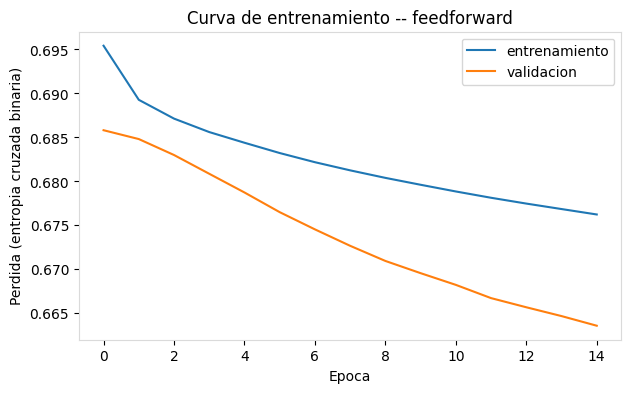

In [14]:
modelo_ff = keras.Sequential([
    layers.Input(shape=(len(columnas_features),)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

modelo_ff.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

hist_ff = modelo_ff.fit(X_train, y_train, epochs=15, batch_size=64,
                         validation_split=0.15, verbose=0)

plt.figure(figsize=(7, 4))
plt.plot(hist_ff.history["loss"], label="entrenamiento")
plt.plot(hist_ff.history["val_loss"], label="validacion")
plt.xlabel("Epoca")
plt.ylabel("Perdida (entropia cruzada binaria)")
plt.title("Curva de entrenamiento -- feedforward")
plt.legend()
plt.show()

Accuracy del modelo feedforward en prueba: 0.385
Baseline ingenuo (predecir siempre la clase mayoritaria): 0.668

              precision    recall  f1-score   support

     no sube       0.59      0.26      0.36       373
        sube       0.30      0.63      0.41       185

    accuracy                           0.39       558
   macro avg       0.44      0.45      0.38       558
weighted avg       0.49      0.39      0.38       558



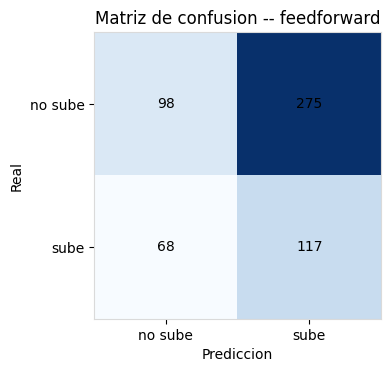

In [15]:
test_loss_ff, test_acc_ff = modelo_ff.evaluate(X_test, y_test, verbose=0)
baseline_clase_mayoritaria = max(y_test.mean(), 1 - y_test.mean())

print(f"Accuracy del modelo feedforward en prueba: {test_acc_ff:.3f}")
print(f"Baseline ingenuo (predecir siempre la clase mayoritaria): {baseline_clase_mayoritaria:.3f}")

pred_ff = (modelo_ff.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print()
print(classification_report(y_test, pred_ff, target_names=["no sube", "sube"]))

cm = confusion_matrix(y_test, pred_ff)
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xticks([0, 1], ["no sube", "sube"])
plt.yticks([0, 1], ["no sube", "sube"])
plt.xlabel("Prediccion")
plt.ylabel("Real")
plt.title("Matriz de confusion -- feedforward")
plt.tight_layout()
plt.show()

# Guardamos el resultado para comparar con CNN, RNN, LSTM y GRU mas adelante
resultados_modelos = {}
resultados_modelos["Feedforward"] = test_acc_ff

**PREGUNTA 4** -- Con datos reales es comun que la red apenas iguale, o incluso quede claramente por
debajo, del baseline ingenuo (revisen los numeros que acaban de imprimir arriba). ¿Es un error del
codigo? Un dato util: en el conjunto de entrenamiento, la clase "sube" es cerca de la mitad de las
observaciones, pero en el conjunto de prueba (los ultimos meses del dataset) es una minoria mucho mas
chica -- es decir, el mercado cambio de regimen entre el periodo de entrenamiento y el de prueba.
¿Que nos dice esto sobre la hipotesis de mercados eficientes, y sobre el riesgo de asumir que un
modelo entrenado en un periodo va a seguir funcionando igual en un periodo con una tendencia distinta
(no estacionariedad)?

- No es un error del código, el modelo si está aprendiendo del conjunto de entrenamiento, el problema 
esta en lo que el modelo está tratando de predecir.
- Este resultado es consistente con la hipótesis de mercados eficientes, solo con los rendimientos pasados
no se puede predecir la dirección futura del precio de forma consistente porque no contienen suficiente 
señal explotable
- En cuanto a la no estacionariedad: al cambiar de régimen de mercado entre entrenamiento y prueba es un 
riesgo en series de tiempo financieras porque el modelo no puede adivinar un cambio de reglas que nunca vio

A partir de aqui vamos a acelerar el ritmo: en las partes 3 y 4 revisamos menos detalle por modelo
(sin matriz de confusion en cada uno) para poder comparar varias arquitecturas en el tiempo que
tenemos.

---
## Parte 3 -- CNN 1D sobre ventanas de rendimientos 

En vez de resumir cada dia en 5 numeros hechos a mano, le damos a la red la **ventana cruda** de los
ultimos 20 rendimientos diarios y dejamos que aprenda sus propios filtros -- exactamente la idea de
convolucion que vimos en la sesion de CNNs, aplicada aqui en una dimension (tiempo) en vez de dos
(imagenes).

In [16]:
VENTANA = 20

def construir_secuencias(precios, ventana=VENTANA, horizonte=HORIZONTE):
    ret = precios.pct_change()
    retornos_arr = ret.values
    precios_arr = precios.values
    fechas_idx = precios.index
    X, y, fechas = [], [], []
    for i in range(ventana, len(precios_arr) - horizonte):
        ventana_ret = retornos_arr[i - ventana:i]
        if np.isnan(ventana_ret).any():
            continue
        retorno_futuro = precios_arr[i + horizonte] / precios_arr[i] - 1
        X.append(ventana_ret)
        y.append(1.0 if retorno_futuro > 0 else 0.0)
        fechas.append(fechas_idx[i])
    return np.array(X, dtype="float32"), np.array(y, dtype="float32"), pd.DatetimeIndex(fechas)

X_list, y_list, fechas_list = [], [], []
for ticker in tickers:
    Xt, yt, ft = construir_secuencias(close[ticker])
    X_list.append(Xt); y_list.append(yt); fechas_list.append(ft)

X_sec = np.concatenate(X_list, axis=0)
y_sec = np.concatenate(y_list, axis=0)
fechas_sec = pd.DatetimeIndex(np.concatenate([f.values for f in fechas_list]))

print(f"Total de secuencias: {len(X_sec)}  (ventana={VENTANA} dias, horizonte={HORIZONTE} dias)")
print(f"Proporcion de la clase 'sube': {y_sec.mean():.3f}")

Total de secuencias: 2898  (ventana=20 dias, horizonte=10 dias)
Proporcion de la clase 'sube': 0.463


In [17]:
corte_sec = fechas_sec.to_series().quantile(0.8)
mask_train = fechas_sec <= corte_sec
mask_test = ~mask_train

X_train_sec, y_train_sec = X_sec[mask_train], y_sec[mask_train]
X_test_sec, y_test_sec = X_sec[mask_test], y_sec[mask_test]
print("Entrenamiento:", X_train_sec.shape, " | Prueba:", X_test_sec.shape)

media_sec = X_train_sec.mean()
desv_sec = X_train_sec.std()
X_train_sec_n = (X_train_sec - media_sec) / desv_sec
X_test_sec_n = (X_test_sec - media_sec) / desv_sec

# Keras espera (muestras, pasos_de_tiempo, canales) para capas Conv1D y recurrentes
X_train_seq = X_train_sec_n[..., np.newaxis]
X_test_seq = X_test_sec_n[..., np.newaxis]
print("Forma de entrada:", X_train_seq.shape)

Entrenamiento: (2322, 20)  | Prueba: (576, 20)
Forma de entrada: (2322, 20, 1)


### La CNN 1D

Dos bloques convolucionales (cada uno aprende filtros que detectan patrones locales en la ventana de
rendimientos, por ejemplo "varios dias seguidos con rendimientos positivos") seguidos de
`GlobalAveragePooling1D` (que resume toda la secuencia en un vector) y una salida sigmoide.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 18, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 9, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 7, 8)           │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465 (1.82 KB)

 Trainable params: 465 (1.82 KB)

 Non-trainable params: 0 (0.00 B)

Accuracy CNN 1D en prueba: 0.453
Accuracy feedforward (Parte 2): 0.385
Baseline ingenuo: 0.668


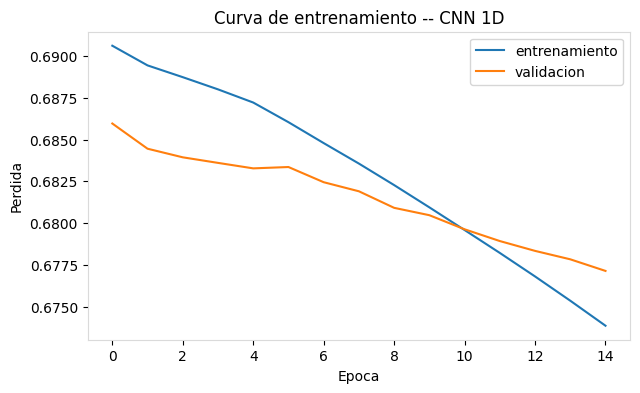

In [18]:
modelo_cnn = keras.Sequential([
    layers.Input(shape=(VENTANA, 1)),
    layers.Conv1D(16, kernel_size=3, activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(8, kernel_size=3, activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(1, activation="sigmoid"),
])

modelo_cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo_cnn.summary()

hist_cnn = modelo_cnn.fit(X_train_seq, y_train_sec, epochs=15, batch_size=64,
                           validation_split=0.15, verbose=0)

test_loss_cnn, test_acc_cnn = modelo_cnn.evaluate(X_test_seq, y_test_sec, verbose=0)
resultados_modelos["CNN 1D"] = test_acc_cnn

print(f"Accuracy CNN 1D en prueba: {test_acc_cnn:.3f}")
print(f"Accuracy feedforward (Parte 2): {resultados_modelos['Feedforward']:.3f}")
print(f"Baseline ingenuo: {baseline_clase_mayoritaria:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(hist_cnn.history["loss"], label="entrenamiento")
plt.plot(hist_cnn.history["val_loss"], label="validacion")
plt.xlabel("Epoca"); plt.ylabel("Perdida")
plt.title("Curva de entrenamiento -- CNN 1D")
plt.legend()
plt.show()

**PREGUNTA 5** -- La CNN recibe la ventana cruda de 20 rendimientos y aprende sus propios filtros,
en vez de que nosotros definamos a mano `ret1`, `ma10`, `ma50`, `vol21` y `mom21` como en la Parte 2.
¿Que ventaja tiene dejar que la red aprenda su propia representacion? ¿Que desventaja tiene, pensando
en cuantos datos hacen falta para que esos filtros se aprendan bien?

- La ventaja que tiene es que le damos, al modelo, la posibilidad de que encuentre algo mejor por si mismo
- La desventaja es que la red tiene que aprender esos filtros desde cero a partir de los datos, en 
vez de que se los demos ya calculados. El problema esta en que aprender bien los filtros útiles necesita 
de muchos más ejemplos que si ya tiene la información resumida.

**RETO 5** -- En la celda de abajo, construyan `modelo_cnn_variante`: una copia de `modelo_cnn`
pero agregando una capa `Dropout(0.3)` justo despues del `GlobalAveragePooling1D` (antes de la capa
`Dense` final). Entrenen esa variante con el mismo `fit()` y comparen su accuracy en prueba contra
`modelo_cnn`. Guarden el resultado en `resultados_modelos["CNN 1D + Dropout"]`.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 18, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 9, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 7, 8)           │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465 (1.82 KB)

 Trainable params: 465 (1.82 KB)

 Non-trainable params: 0 (0.00 B)

Accuracy CNN 1D + Dropout en prueba: 0.564
Accuracy feedforward (Parte 2): 0.385
Baseline ingenuo: 0.668


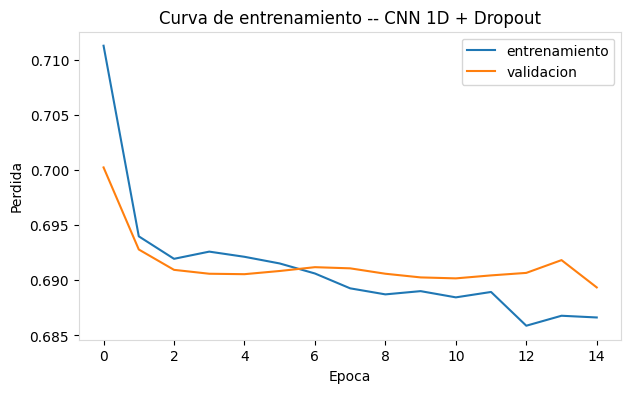

In [19]:
# RETO 5 -- espacio para su codigo (modelo_cnn_variante con Dropout)
modelo_cnn_variante = keras.Sequential([
    layers.Input(shape=(VENTANA, 1)),
    layers.Conv1D(16, kernel_size=3, activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(8, kernel_size=3, activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])

modelo_cnn_variante.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo_cnn_variante.summary()

hist_cnn = modelo_cnn_variante.fit(X_train_seq, y_train_sec, epochs=15, batch_size=64,
                           validation_split=0.15, verbose=0)

test_loss_cnn, test_acc_cnn = modelo_cnn_variante.evaluate(X_test_seq, y_test_sec, verbose=0)
resultados_modelos["CNN 1D + Dropout"] = test_acc_cnn

print(f"Accuracy CNN 1D + Dropout en prueba: {test_acc_cnn:.3f}")
print(f"Accuracy feedforward (Parte 2): {resultados_modelos['Feedforward']:.3f}")
print(f"Baseline ingenuo: {baseline_clase_mayoritaria:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(hist_cnn.history["loss"], label="entrenamiento")
plt.plot(hist_cnn.history["val_loss"], label="validacion")
plt.xlabel("Epoca"); plt.ylabel("Perdida")
plt.title("Curva de entrenamiento -- CNN 1D + Dropout")
plt.legend()
plt.show()

---
## Parte 4 -- RNN, LSTM y GRU sobre las mismas ventanas 

Usamos exactamente las mismas secuencias (`X_train_seq`, `X_test_seq`) que en la Parte 3, pero ahora
las procesamos de forma **secuencial**, un paso de tiempo a la vez, con una celda recurrente -- la
diferencia clave frente a la CNN es que una RNN mantiene un "estado" que va acumulando informacion a
lo largo de la ventana, en vez de mirar patrones locales con un filtro fijo.

In [21]:
def construir_recurrente(tipo_celda="LSTM", unidades=16):
    if tipo_celda == "SimpleRNN":
        capa_recurrente = layers.SimpleRNN(unidades)
    elif tipo_celda == "LSTM":
        capa_recurrente = layers.LSTM(unidades)
    elif tipo_celda == "GRU":
        # RETO 6 -- agreguen la rama para GRU (pista: layers.GRU(unidades), igual que las otras dos)
        capa_recurrente = layers.GRU(unidades)
    else:
        raise ValueError(f"tipo_celda no reconocido: {tipo_celda}")

    modelo = keras.Sequential([
        layers.Input(shape=(VENTANA, 1)),
        capa_recurrente,
        layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

for tipo in ["SimpleRNN", "LSTM"]:
    modelo_r = construir_recurrente(tipo)
    hist_r = modelo_r.fit(X_train_seq, y_train_sec, epochs=15, batch_size=64,
                           validation_split=0.15, verbose=0)
    _, acc_r = modelo_r.evaluate(X_test_seq, y_test_sec, verbose=0)
    resultados_modelos[tipo] = acc_r
    print(f"Accuracy {tipo} en prueba: {acc_r:.3f}")

Accuracy SimpleRNN en prueba: 0.512
Accuracy LSTM en prueba: 0.457


**PREGUNTA 6** -- En la Sesion 5 vimos que, sobre una secuencia larga, el gradiente de una
SimpleRNN puede volverse extremadamente pequeño (vanishing gradient) al propagarse hacia atras en el
tiempo, mientras que LSTM y GRU usan compuertas (gates) que evitan ese colapso. Con una ventana de solo
20 dias, ¿esperarian una diferencia grande entre SimpleRNN, LSTM y GRU? ¿Con una ventana de 200 dias,
cambiaria su respuesta?

- La diferencia entre SimpleRNN, LSTM y GRU, con una ventana de 20 días, puede llegar a ser moderada o 
pequeña, dependiendo de la complejidad del problema. Aunque si la predicción del día 21 requiere asociar 
de un evento del día 1 con el del día 20, LSTM y GRU van a mostrar un mejor desempeño.
- Con una ventana de 200 días cambia totalmente la respuesta. En este escenario, la diferencia entre la 
SimpleRNN y LSTM/GRU será muy significativa, ya que la SimplRNN es incapaz de aprender dependencias tan 
lejanas.

**RETO 6** -- Completen la rama de `GRU` en `construir_recurrente` (arriba, donde dice
`# RETO 6`) usando `layers.GRU(unidades)`, igual que las otras dos ramas. Despues, en la celda de
abajo, entrenen un modelo con `tipo_celda="GRU"` siguiendo el mismo patron del ciclo `for` de arriba,
y guarden el resultado en `resultados_modelos["GRU"]`.

In [22]:
# RETO 6 -- espacio para su codigo (entrenar y evaluar el modelo GRU)
modelo_gru = construir_recurrente("GRU")
hist_gru = modelo_gru.fit(X_train_seq, y_train_sec, epochs=15, batch_size=64,
                           validation_split=0.15, verbose=0)
_, acc_gru = modelo_gru.evaluate(X_test_seq, y_test_sec, verbose=0)
resultados_modelos["GRU"] = acc_gru
print(f"Accuracy GRU en prueba: {acc_gru:.3f}")

Accuracy GRU en prueba: 0.576


### Comparacion de las cinco arquitecturas sobre la misma tarea

Un mismo problema (¿sube el precio en los proximos 10 dias?), resuelto con Feedforward, CNN 1D y
celdas recurrentes. El grafico de abajo usa lo que haya en `resultados_modelos` -- si ya completaron
los RETO 5 y 6, tambien apareceran esas dos variantes.

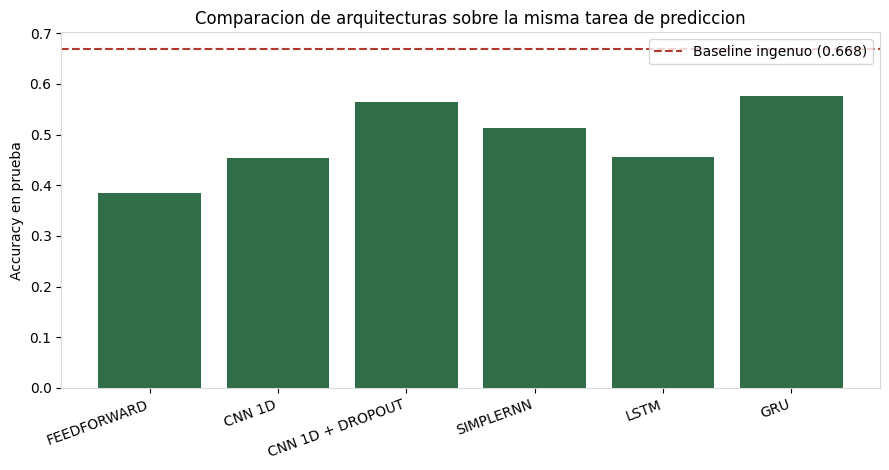

  Feedforward            0.385
  CNN 1D                 0.453
  CNN 1D + Dropout       0.564
  SimpleRNN              0.512
  LSTM                   0.457
  GRU                    0.576


In [23]:
nombres = list(resultados_modelos.keys())
valores = list(resultados_modelos.values())
etiquetas = [n.upper() for n in nombres]

plt.figure(figsize=(9, 4.8))
plt.bar(etiquetas, valores, color=DARKGREEN)
plt.axhline(baseline_clase_mayoritaria, color=RED, linestyle="--",
            label=f"Baseline ingenuo ({baseline_clase_mayoritaria:.3f})")
plt.ylabel("Accuracy en prueba")
plt.title("Comparacion de arquitecturas sobre la misma tarea de prediccion")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

for nombre, valor in resultados_modelos.items():
    print(f"  {nombre:22s} {valor:.3f}")

Con datos reales de un periodo relativamente corto (menos de dos años) y un cambio de tendencia
marcado hacia el final del dataset, es normal que **ninguna** arquitectura supere de forma consistente
al baseline ingenuo -- ni la mas simple (Feedforward) ni las mas sofisticadas (LSTM, GRU). Esto no
es un fracaso del taller: es el mismo mensaje de la Pregunta 4, reforzado con cinco arquitecturas
distintas en vez de una sola. La arquitectura correcta no compensa un cambio de regimen de mercado que
ninguna de las dos particiones (entrenamiento y prueba) anticipaba.

---
## Parte 5 -- Autoencoders: imputacion de datos y limpieza de covarianza 

Dos usos muy distintos del mismo tipo de red: rellenar huecos en los datos, y reducir el ruido
estadistico de una matriz de covarianza antes de usarla para optimizar un portafolio.

### 5.1 Imputacion de datos faltantes

**Contexto:** en la practica, las bases de datos financieras reales casi siempre tienen huecos: caidas
de un exchange, fallas al reportar un precio, feriados que no coinciden entre mercados, etc.

**Metodologia:** partimos de datos reales sin huecos, y **ocultamos artificialmente** un porcentaje de
los valores (los reemplazamos por "faltante") para poder evaluar que tan buena es la imputacion contra
el valor verdadero.

In [24]:
rng = np.random.default_rng(7)

media_ret = rendimientos.mean()
desv_ret = rendimientos.std()
Z_real = ((rendimientos - media_ret) / desv_ret).values.astype("float32")
n_dias, _ = Z_real.shape

PORC_OCULTO = 0.15
mascara = rng.random(size=Z_real.shape) < PORC_OCULTO  # True = valor real oculto

Z_dañado = Z_real.copy()
Z_dañado[mascara] = 0.0  # 0 = "no disponible" en la escala normalizada

print(f"Celdas ocultas: {mascara.sum()} de {mascara.size} ({mascara.mean():.1%})")

Celdas ocultas: 448 de 3078 (14.6%)


El autoencoder se entrena con **aumento de datos**: en cada epoca generamos una mascara aleatoria
distinta, para que aprenda a reconstruir un valor faltante sin importar cual de las 6 monedas sea la
que falte, apoyandose en como se mueven las demas ese mismo dia.

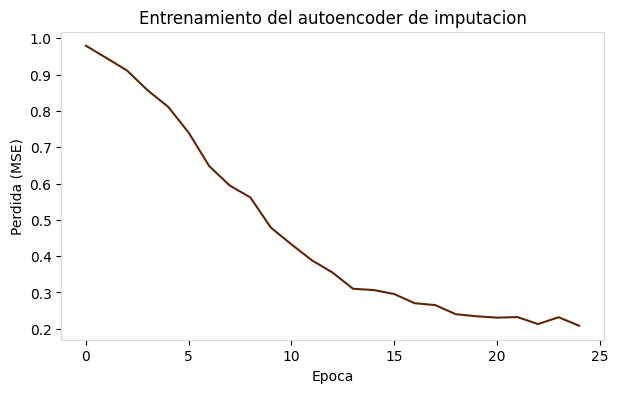

In [25]:
class AumentoMascaraAleatoria(keras.utils.PyDataset):
    def __init__(self, datos, batch_size=64, porc_oculto=0.2, seed=0, **kwargs):
        super().__init__(**kwargs)
        self.datos = datos
        self.batch_size = batch_size
        self.porc_oculto = porc_oculto
        self.rng = np.random.default_rng(seed)
        self.n = datos.shape[0]

    def __len__(self):
        return int(np.ceil(self.n / self.batch_size))

    def __getitem__(self, idx):
        lote = self.datos[idx * self.batch_size:(idx + 1) * self.batch_size].copy()
        m = self.rng.random(size=lote.shape) < self.porc_oculto
        x = lote.copy()
        x[m] = 0.0
        return x, lote

generador = AumentoMascaraAleatoria(Z_real, batch_size=64, porc_oculto=0.2, seed=1)

latent_dim_imputacion = 3
entrada_imp = keras.Input(shape=(n_activos,))
h = layers.Dense(16, activation="relu")(entrada_imp)
h = layers.Dense(latent_dim_imputacion, activation="relu")(h)
h = layers.Dense(16, activation="relu")(h)
salida_imp = layers.Dense(n_activos, activation="linear")(h)

autoencoder_imputacion = keras.Model(entrada_imp, salida_imp)
autoencoder_imputacion.compile(optimizer="adam", loss="mse")
hist_imp = autoencoder_imputacion.fit(generador, epochs=25, verbose=0)

plt.figure(figsize=(7, 4))
plt.plot(hist_imp.history["loss"], color=BROWN)
plt.xlabel("Epoca"); plt.ylabel("Perdida (MSE)")
plt.title("Entrenamiento del autoencoder de imputacion")
plt.show()

In [26]:
reconstruido = autoencoder_imputacion.predict(Z_dañado, verbose=0)
imputado = np.where(mascara, reconstruido, Z_dañado)

error_autoencoder = np.abs(imputado[mascara] - Z_real[mascara]).mean()

# baseline: imputar con la media de cada columna (que en datos normalizados es 0)
imputado_baseline = np.zeros_like(Z_dañado)
error_baseline = np.abs(imputado_baseline[mascara] - Z_real[mascara]).mean()

print(f"MAE -- imputacion con autoencoder: {error_autoencoder:.4f}")
print(f"MAE -- imputacion con la media de la columna: {error_baseline:.4f}")
mejora = (error_baseline - error_autoencoder) / error_baseline
print(f"Mejora relativa sobre el baseline: {mejora:.1%}")

MAE -- imputacion con autoencoder: 0.3108
MAE -- imputacion con la media de la columna: 0.6779
Mejora relativa sobre el baseline: 54.2%


**PREGUNTA 7** -- ¿Por que el autoencoder gana al baseline de "imputar con la media"? Piensen en
que informacion adicional tiene el autoencoder que no tiene un promedio simple por columna (pista:
piensen en que tan correlacionadas suelen moverse las criptomonedas el mismo dia).

- La ventaja del autoencoder es que utiliza la correlación cruzada entre columnas en el mismo día, 
en cambio la media solo usa la historia de esa columna.

**RETO 7** -- En la celda de abajo, repitan el experimento completo (mascara, entrenamiento y
medicion de error) con `PORC_OCULTO = 0.4` (40% de datos faltantes en vez de 15%). Usen nombres de
variables distintos (por ejemplo `mascara_40`, `error_autoencoder_40`) para no sobreescribir los
resultados de arriba. ¿Que tan rapido se degrada la calidad de la imputacion en comparacion con el
baseline, conforme sube el porcentaje de datos faltantes?

Celdas ocultas: 448 de 3078 (14.6%)


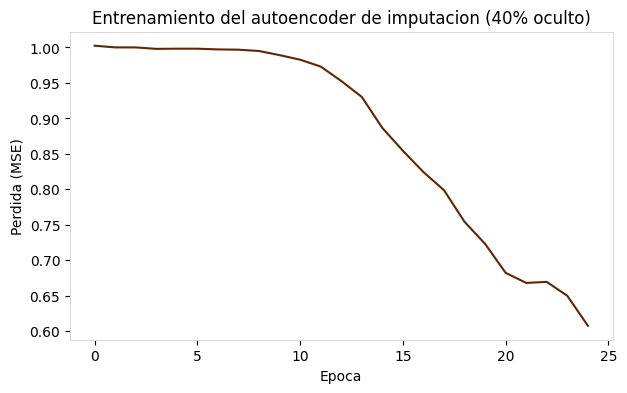

MAE -- imputacion con autoencoder (40%): 0.4972
MAE -- imputacion con la media de la columna (40%): 0.6781
Mejora relativa sobre el baseline (40%): 26.7%


In [27]:
# RETO 7 -- espacio para su codigo (PORC_OCULTO = 0.4)
PORC_OCULTO_40 = 0.4
mascara_40 = rng.random(size=Z_real.shape) < PORC_OCULTO_40

Z_dañado_40 = Z_real.copy()
Z_dañado_40[mascara_40] = 0.0

print(f"Celdas ocultas: {mascara.sum()} de {mascara.size} ({mascara.mean():.1%})")

generador_40 = AumentoMascaraAleatoria(Z_real, batch_size=64, porc_oculto=0.4, seed=1)

entrada_imp_40 = keras.Input(shape=(n_activos,))
h = layers.Dense(16, activation="relu")(entrada_imp_40)
h = layers.Dense(latent_dim_imputacion, activation="relu")(h)
h = layers.Dense(16, activation="relu")(h)
salida_imp_40 = layers.Dense(n_activos, activation="linear")(h)

autoencoder_imputacion_40 = keras.Model(entrada_imp_40, salida_imp_40)
autoencoder_imputacion_40.compile(optimizer="adam", loss="mse")
hist_imp_40 = autoencoder_imputacion_40.fit(generador_40, epochs=25, verbose=0)

plt.figure(figsize=(7, 4))
plt.plot(hist_imp_40.history["loss"], color=BROWN)
plt.xlabel("Epoca"); plt.ylabel("Perdida (MSE)")
plt.title("Entrenamiento del autoencoder de imputacion (40% oculto)")
plt.show()

reconstruido_40 = autoencoder_imputacion_40.predict(Z_dañado_40, verbose=0)
imputado_40 = np.where(mascara_40, reconstruido_40, Z_dañado_40)

error_autoencoder_40 = np.abs(imputado_40[mascara_40] - Z_real[mascara_40]).mean()

imputado_baseline_40 = np.zeros_like(Z_dañado_40)
error_baseline_40 = np.abs(imputado_baseline_40[mascara_40] - Z_real[mascara_40]).mean()

print(f"MAE -- imputacion con autoencoder (40%): {error_autoencoder_40:.4f}")
print(f"MAE -- imputacion con la media de la columna (40%): {error_baseline_40:.4f}")
mejora_40 = (error_baseline_40 - error_autoencoder_40) / error_baseline_40
print(f"Mejora relativa sobre el baseline (40%): {mejora_40:.1%}")

### 5.2 Autoencoders para "limpiar" una matriz de covarianza

Las covarianzas estimadas directamente de datos historicos suelen tener mucho ruido estadistico. Una
tecnica real, usada en gestion cuantitativa de riesgo, es entrenar un autoencoder sobre los
rendimientos y usar su **reconstruccion** (no los datos crudos) para estimar la covarianza -- el
cuello de botella descarta parte del ruido idiosincratico de cada activo y conserva sobre todo los
movimientos que comparten varios activos a la vez (factores comunes de mercado).

In [28]:
corte_fecha = rendimientos.index[int(len(rendimientos) * 0.8)]
ret_train = rendimientos[rendimientos.index <= corte_fecha]
ret_test = rendimientos[rendimientos.index > corte_fecha]

media_train = ret_train.mean()
desv_train = ret_train.std()
Z_train = ((ret_train - media_train) / desv_train).values.astype("float32")

latent_dim_cov = 2
entrada_cov = keras.Input(shape=(n_activos,))
h = layers.Dense(12, activation="relu")(entrada_cov)
h = layers.Dense(latent_dim_cov, activation="relu")(h)
h = layers.Dense(12, activation="relu")(h)
salida_cov = layers.Dense(n_activos, activation="linear")(h)

autoencoder_cov = keras.Model(entrada_cov, salida_cov)
autoencoder_cov.compile(optimizer="adam", loss="mse")
autoencoder_cov.fit(Z_train, Z_train, epochs=40, batch_size=32, validation_split=0.1, verbose=0)

Z_denoised = autoencoder_cov.predict(Z_train, verbose=0)
ret_denoised = pd.DataFrame(Z_denoised * desv_train.values + media_train.values,
                             index=ret_train.index, columns=tickers)

cov_cruda = ret_train.cov() * 252
cov_denoised = ret_denoised.cov() * 252
rendimiento_esperado = ret_train.mean() * 252

diferencia = np.linalg.norm(cov_cruda.values - cov_denoised.values)
print(f"Diferencia (norma de Frobenius) entre covarianza cruda y denoised: {diferencia:.3f}")

Diferencia (norma de Frobenius) entre covarianza cruda y denoised: 0.943


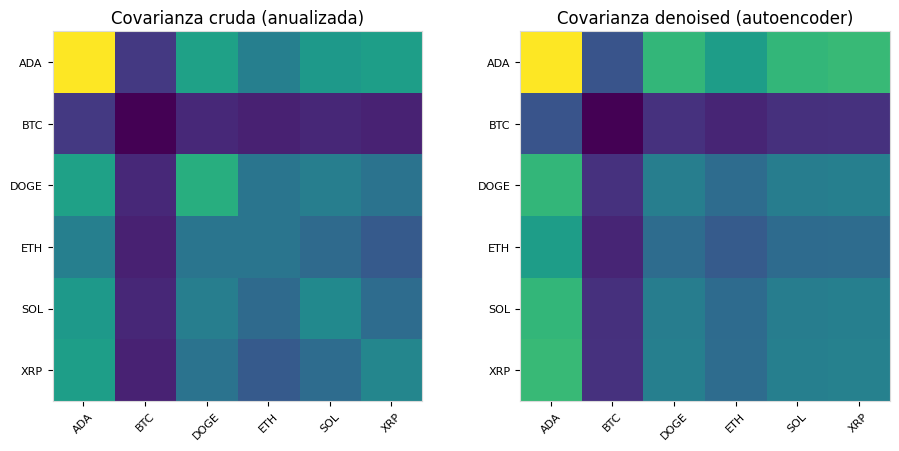

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.5))
axes[0].imshow(cov_cruda, cmap="viridis")
axes[0].set_title("Covarianza cruda (anualizada)")
axes[1].imshow(cov_denoised, cmap="viridis")
axes[1].set_title("Covarianza denoised (autoencoder)")
for ax in axes:
    ax.set_xticks(range(n_activos)); ax.set_xticklabels(tickers, rotation=45, fontsize=8)
    ax.set_yticks(range(n_activos)); ax.set_yticklabels(tickers, fontsize=8)
plt.tight_layout()
plt.show()

**PREGUNTA 8** -- ¿Que pasaria si `latent_dim_cov` fuera muy chico (por ejemplo, 1)? ¿Y si fuera
igual a `n_activos` (6, es decir, sin ninguna compresion)? Piensen en el balance entre "descartar
demasiado" y "no limpiar nada".

- Si latent_dim_cov fuera 1, descartaríamos demasiada infromación y parecería que los activos se mueven como una sola cosa, perdiendo infromación útil y no solo ruido.
- Si fuera igual al número de activos, el autoencoder no estaría forzado a resumir nada y se perdería el beneficio de haber utilizado el autoencoder.

**RETO 8** -- En la celda de abajo, entrenen su propia version de `autoencoder_cov` con
`latent_dim_cov = 1` (en vez de 2) y calculen la nueva diferencia (norma de Frobenius) contra la
covarianza cruda. Usen nombres nuevos para no sobreescribir los resultados de arriba (por ejemplo
`autoencoder_cov_1`, `cov_denoised_1`). ¿La diferencia es mayor o menor que con `latent_dim_cov = 2`?

In [30]:
# RETO 8 -- espacio para su codigo (latent_dim_cov = 1)
latent_dim_cov_1 = 1
entrada_cov_1 = keras.Input(shape=(n_activos,))
h = layers.Dense(12, activation="relu")(entrada_cov_1)
h = layers.Dense(latent_dim_cov_1, activation="relu")(h)
h = layers.Dense(12, activation="relu")(h)
salida_cov_1 = layers.Dense(n_activos, activation="linear")(h)

autoencoder_cov_1 = keras.Model(entrada_cov_1, salida_cov_1)
autoencoder_cov_1.compile(optimizer="adam", loss="mse")
autoencoder_cov_1.fit(Z_train, Z_train, epochs=40, batch_size=32, validation_split=0.1, verbose=0)

Z_denoised_1 = autoencoder_cov_1.predict(Z_train, verbose=0)
ret_denoised_1 = pd.DataFrame(Z_denoised_1 * desv_train.values + media_train.values,
                               index=ret_train.index, columns=tickers)

cov_denoised_1 = ret_denoised_1.cov() * 252

diferencia_1 = np.linalg.norm(cov_cruda.values - cov_denoised_1.values)
print(f"Diferencia (norma de Frobenius) entre covarianza cruda y denoised (latent_dim=1): {diferencia_1:.3f}")
print(f"Diferencia con latent_dim_cov=2 (arriba): {diferencia:.3f}")

Diferencia (norma de Frobenius) entre covarianza cruda y denoised (latent_dim=1): 1.304
Diferencia con latent_dim_cov=2 (arriba): 0.943


---
## Parte 6 -- Portafolios de inversion: Markowitz sobre la covarianza limpia 

Con los rendimientos esperados (media historica real anualizada) y la matriz de covarianza denoised de
la Parte 5, calculamos la frontera eficiente, el portafolio de minima varianza global (GMV) y el
portafolio de maximo Sharpe ratio -- sobre un portafolio de 6 criptomonedas.

**Aviso:** este taller es un ejercicio educativo sobre optimizacion de portafolios y redes neuronales.
No es una recomendacion de inversion -- los resultados dependen enteramente del periodo historico
usado (menos de dos años, y ademas un periodo de alta volatilidad tipico de las criptomonedas), y el
desempeño pasado no garantiza resultados futuros.

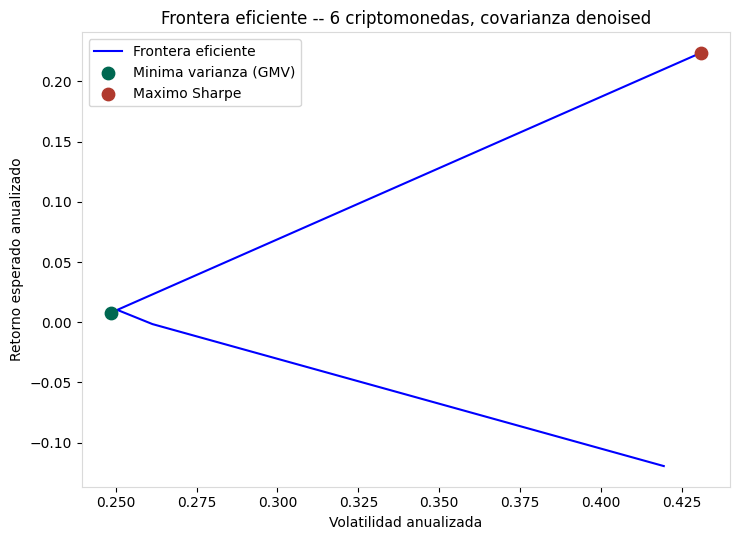

GMV       -> retorno esperado: 0.008  volatilidad: 0.249
MaxSharpe -> retorno esperado: 0.224  volatilidad: 0.431  Sharpe: 0.47

Pesos GMV:       {'ADA': np.float64(0.0), 'BTC': np.float64(1.0), 'DOGE': np.float64(0.0), 'ETH': np.float64(0.0), 'SOL': np.float64(0.0), 'XRP': np.float64(0.0)}
Pesos MaxSharpe: {'ADA': np.float64(0.0), 'BTC': np.float64(0.0), 'DOGE': np.float64(0.0), 'ETH': np.float64(1.0), 'SOL': np.float64(0.0), 'XRP': np.float64(0.0)}


In [31]:
def desempeño_portafolio(pesos, rendimiento_esperado, cov):
    retorno = pesos @ rendimiento_esperado
    volatilidad = np.sqrt(pesos @ cov @ pesos)
    return retorno, volatilidad

def portafolio_min_varianza_con_retorno(retorno_objetivo, rendimiento_esperado, cov):
    n = len(rendimiento_esperado)
    x0 = np.ones(n) / n
    restricciones = [
        {"type": "eq", "fun": lambda w: np.sum(w) - 1},
        {"type": "eq", "fun": lambda w: w @ rendimiento_esperado - retorno_objetivo},
    ]
    return minimize(lambda w: w @ cov @ w, x0, bounds=[(0, 1)] * n, constraints=restricciones)

objetivos = np.linspace(rendimiento_esperado.min() * 0.5, rendimiento_esperado.max() * 0.995, 30)
frontera = []
for objetivo in objetivos:
    res = portafolio_min_varianza_con_retorno(objetivo, rendimiento_esperado.values, cov_denoised.values)
    if res.success:
        ret, vol = desempeño_portafolio(res.x, rendimiento_esperado.values, cov_denoised.values)
        frontera.append((vol, ret))
frontera = np.array(frontera)

res_gmv = minimize(lambda w: w @ cov_denoised.values @ w, np.ones(n_activos) / n_activos,
                    bounds=[(0, 1)] * n_activos,
                    constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}])
pesos_gmv = res_gmv.x
ret_gmv, vol_gmv = desempeño_portafolio(pesos_gmv, rendimiento_esperado.values, cov_denoised.values)

tasa_libre_riesgo = 0.02
res_sharpe = minimize(
    lambda w: -(w @ rendimiento_esperado.values - tasa_libre_riesgo) / np.sqrt(w @ cov_denoised.values @ w),
    np.ones(n_activos) / n_activos, bounds=[(0, 1)] * n_activos,
    constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1}],
)
pesos_sharpe = res_sharpe.x
ret_sharpe, vol_sharpe = desempeño_portafolio(pesos_sharpe, rendimiento_esperado.values, cov_denoised.values)

plt.figure(figsize=(7.5, 5.5))
plt.plot(frontera[:, 0], frontera[:, 1], "b-", label="Frontera eficiente")
plt.scatter(vol_gmv, ret_gmv, color=GREEN, s=80, zorder=5, label="Minima varianza (GMV)")
plt.scatter(vol_sharpe, ret_sharpe, color=RED, s=80, zorder=5, label="Maximo Sharpe")
plt.xlabel("Volatilidad anualizada")
plt.ylabel("Retorno esperado anualizado")
plt.title("Frontera eficiente -- 6 criptomonedas, covarianza denoised")
plt.legend()
plt.tight_layout()
plt.show()

print(f"GMV       -> retorno esperado: {ret_gmv:.3f}  volatilidad: {vol_gmv:.3f}")
print(f"MaxSharpe -> retorno esperado: {ret_sharpe:.3f}  volatilidad: {vol_sharpe:.3f}  "
      f"Sharpe: {(ret_sharpe - tasa_libre_riesgo) / vol_sharpe:.2f}")
print()
print("Pesos GMV:      ", {t: round(w, 3) for t, w in zip(tickers, pesos_gmv)})
print("Pesos MaxSharpe:", {t: round(w, 3) for t, w in zip(tickers, pesos_sharpe)})

Con solo 6 activos y un periodo relativamente corto y volatil, no es raro que el optimizador
encuentre una **solucion de esquina**: casi todo el peso concentrado en un solo activo (el que tuvo el
mejor retorno esperado historico), en vez de un portafolio diversificado. Revisen los pesos que se
acaban de imprimir. Ningun inversionista serio pondria el 100% de su dinero en un solo activo -- esto
es precisamente el problema de "maximizacion del error" de Markowitz: el optimizador toma al pie de la
letra una estimacion de `rendimiento_esperado` que tiene mucha incertidumbre, y la explota al maximo.

**RETO 9** -- En la celda de abajo, calculen el retorno, la volatilidad y el Sharpe ratio de un
portafolio de **pesos iguales** (cada una de las 6 monedas con peso `1/6`), usando la funcion
`desempeño_portafolio` que ya esta definida arriba. Comparen su Sharpe ratio contra el de GMV y el de
MaxSharpe.

In [32]:
# RETO 9 -- espacio para su codigo (portafolio de pesos iguales)
pesos_iguales = np.ones(n_activos) / n_activos

ret_iguales, vol_iguales = desempeño_portafolio(pesos_iguales, rendimiento_esperado.values, cov_denoised.values)
sharpe_iguales = (ret_iguales - tasa_libre_riesgo) / vol_iguales

print(f"Pesos iguales -> retorno esperado: {ret_iguales:.3f}  volatilidad: {vol_iguales:.3f}  "
      f"Sharpe: {sharpe_iguales:.3f}")

sharpe_gmv = (ret_gmv - tasa_libre_riesgo) / vol_gmv
sharpe_sharpe = (ret_sharpe - tasa_libre_riesgo) / vol_sharpe

print(f"GMV           -> Sharpe: {sharpe_gmv:.3f}")
print(f"MaxSharpe     -> Sharpe: {sharpe_sharpe:.3f}")
print(f"Pesos iguales -> Sharpe: {sharpe_iguales:.3f}")

Pesos iguales -> retorno esperado: -0.052  volatilidad: 0.479  Sharpe: -0.151
GMV           -> Sharpe: -0.048
MaxSharpe     -> Sharpe: 0.473
Pesos iguales -> Sharpe: -0.151


### Backtest fuera de muestra

Aplicamos los pesos calculados con datos de entrenamiento al periodo de prueba (que el optimizador
nunca vio) y comparamos contra un portafolio ingenuo de pesos iguales.

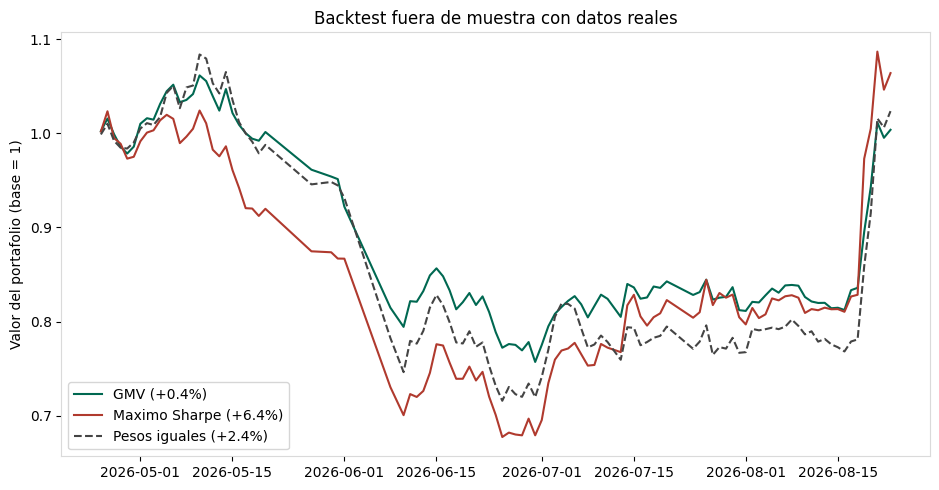

In [33]:
retorno_test_gmv = ret_test.values @ pesos_gmv
retorno_test_sharpe = ret_test.values @ pesos_sharpe
retorno_test_igual = ret_test.values.mean(axis=1)

valor_gmv = (1 + retorno_test_gmv).cumprod()
valor_sharpe = (1 + retorno_test_sharpe).cumprod()
valor_igual = (1 + retorno_test_igual).cumprod()

plt.figure(figsize=(9.5, 5))
plt.plot(ret_test.index, valor_gmv, label=f"GMV ({valor_gmv[-1]-1:+.1%})", color=GREEN)
plt.plot(ret_test.index, valor_sharpe, label=f"Maximo Sharpe ({valor_sharpe[-1]-1:+.1%})", color=RED)
plt.plot(ret_test.index, valor_igual, label=f"Pesos iguales ({valor_igual[-1]-1:+.1%})",
         color=GRAY, linestyle="--")
plt.ylabel("Valor del portafolio (base = 1)")
plt.title("Backtest fuera de muestra con datos reales")
plt.legend()
plt.tight_layout()
plt.show()

**PREGUNTA 9** -- El portafolio que se ve mejor en el periodo de entrenamiento no siempre gana en
el backtest fuera de muestra, y ademas puede terminar concentrado en un solo activo (como acaban de ver
arriba). ¿Por que? Piensen en que los pesos se calcularon usando `rendimiento_esperado` y `cov_denoised`
de **un solo periodo historico**, en la relacion entre esto y la idea de overfitting que ya vimos con
redes neuronales, y en que un portafolio 100% concentrado en un activo es, en la practica, mucho mas
riesgoso que lo que sugiere su volatilidad historica calculada sobre ese mismo periodo.

- rendimiento_esperado y cov_denoised se calcularon usando solo un periodo histórico, por lo que se confunde suerte con habilidad. Si un activo tuvo el mejor retorno por casulidad, el modelo lo toma como verdad absoluta. Esa consentración en un solo activo se vuelve tan riesgoso en la práctica porque si ese activo tiene un mal periodo que no se parecio al pasado, no hay ningún otro activo, en el portafolio, que compense la caída.

---
## Parte 7 -- Medicion de riesgo: VaR y una mirada a CVA 

Ya tenemos un portafolio (usamos el de maximo Sharpe). Ahora medimos que tan grande podria ser una
perdida, con dos metodos distintos de Valor en Riesgo (VaR).

VaR historico al 95%: 0.0334 (en un dia, con 95% de confianza, no se pierde mas de 3.34%)


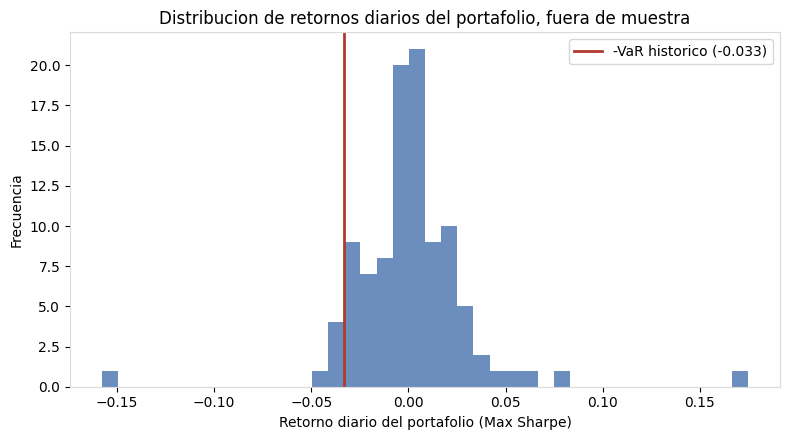

In [34]:
retorno_diario_portafolio = ret_test.values @ pesos_sharpe

nivel_confianza = 0.95

# VaR historico: el percentil de las perdidas observadas, sin asumir ninguna distribucion
VaR_historico = -np.percentile(retorno_diario_portafolio, (1 - nivel_confianza) * 100)

print(f"VaR historico al {nivel_confianza:.0%}: {VaR_historico:.4f} "
      f"(en un dia, con {nivel_confianza:.0%} de confianza, no se pierde mas de {VaR_historico:.2%})")

plt.figure(figsize=(8, 4.5))
plt.hist(retorno_diario_portafolio, bins=40, color=BLUE, alpha=0.7)
plt.axvline(-VaR_historico, color=RED, lw=2, label=f"-VaR historico ({-VaR_historico:.3f})")
plt.xlabel("Retorno diario del portafolio (Max Sharpe)")
plt.ylabel("Frecuencia")
plt.title("Distribucion de retornos diarios del portafolio, fuera de muestra")
plt.legend()
plt.tight_layout()
plt.show()

**RETO 10** -- En la celda de abajo, calculen el **VaR parametrico** (tambien llamado VaR Normal),
que asume que los retornos siguen una distribucion normal:

```
VaR_parametrico = -(media_retorno + z * desviacion_retorno)
```

donde `z` es el cuantil de la distribucion normal estandar para el nivel de confianza deseado (pueden
obtenerlo con `stats.norm.ppf(1 - nivel_confianza)`, ya importado `scipy.stats as stats` al inicio del
notebook). Comparen el VaR parametrico contra el VaR historico que ya calculamos. ¿Son parecidos? ¿Cual
esperarian que sea mas confiable si la distribucion real tiene "colas gordas" (eventos extremos mas
frecuentes que en una normal, algo tipico en criptomonedas)?

In [37]:
# RETO 10 -- espacio para su codigo (VaR parametrico)
z = stats.norm.ppf(1 - nivel_confianza)
media_retorno = retorno_diario_portafolio.mean()
desviacion_retorno = retorno_diario_portafolio.std()

VaR_parametrico = -(media_retorno + z * desviacion_retorno)

print(f"VaR parametrico al {nivel_confianza:.0%}: {VaR_parametrico:.4f}")

VaR parametrico al 95%: 0.0513


### Una mirada a CVA (Credit Value Adjustment) via simulacion Monte Carlo

El CVA ajusta el valor de un instrumento financiero por el riesgo de que la contraparte incumpla. Una
forma de estimarlo es simulando muchas trayectorias posibles del valor futuro de la exposicion y
promediando la perdida esperada. Aqui hacemos una version muy simplificada: simulamos trayectorias del
valor de un portafolio (usando el mismo retorno y volatilidad anualizados del portafolio de maximo
Sharpe) y estimamos la exposicion positiva esperada a un año.

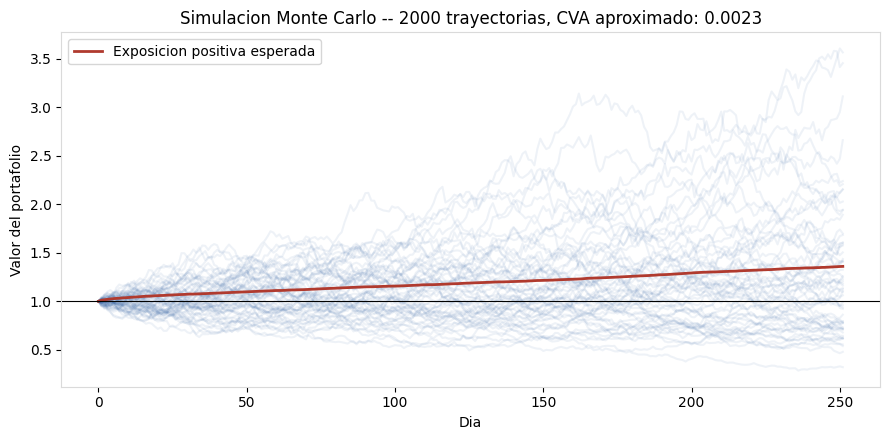

In [ ]:
n_simulaciones = 2000
horizonte_dias = 252
valor_inicial = 1.0

mu_diario = ret_sharpe / 252
sigma_diario = vol_sharpe / np.sqrt(252)

rng_mc = np.random.default_rng(11)
trayectorias = np.zeros((n_simulaciones, horizonte_dias))
trayectorias[:, 0] = valor_inicial * (1 + rng_mc.normal(mu_diario, sigma_diario))
for t in range(1, horizonte_dias):
    trayectorias[:, t] = trayectorias[:, t - 1] * (1 + rng_mc.normal(mu_diario, sigma_diario, n_simulaciones))

exposicion_positiva = np.maximum(trayectorias - valor_inicial, 0)
exposicion_positiva_esperada = exposicion_positiva.mean(axis=0)

prob_incumplimiento_anual = 0.02  # supuesto simplificado de la contraparte
perdida_dado_incumplimiento = 0.6  # supuesto simplificado (60% de la exposicion se pierde)
cva_aproximado = prob_incumplimiento_anual * perdida_dado_incumplimiento * exposicion_positiva_esperada.mean()

plt.figure(figsize=(9, 4.5))
for i in range(60):
    plt.plot(trayectorias[i], color=BLUE, alpha=0.08)
plt.plot(exposicion_positiva_esperada + valor_inicial, color=RED, lw=2, label="Exposicion positiva esperada")
plt.axhline(valor_inicial, color="black", lw=0.8)
plt.title(f"Simulacion Monte Carlo -- {n_simulaciones} trayectorias, CVA aproximado: {cva_aproximado:.4f}")
plt.xlabel("Dia"); plt.ylabel("Valor del portafolio")
plt.legend()
plt.tight_layout()
plt.show()

**RETO 11 (opcional, si el tiempo lo permite)** -- En la celda de abajo, repitan la simulacion
con `n_simulaciones = 200` (en vez de 2000) y con `n_simulaciones = 20000`. Usen nombres de variables
nuevos para cada version. Comparen el `cva_aproximado` de las tres versiones (200, 2000 y 20000). ¿Que
le pasa a la estabilidad de la estimacion conforme aumentan las simulaciones?

In [39]:
# RETO 11 (opcional) -- espacio para su codigo (n_simulaciones = 200, 2000 y 20000)

# --- 200 simulaciones ---
n_simulaciones_200 = 200
horizonte_dias = 252
valor_inicial = 1.0

mu_diario = ret_sharpe / 252
sigma_diario = vol_sharpe / np.sqrt(252)

rng_mc_200 = np.random.default_rng(11)
trayectorias_200 = np.zeros((n_simulaciones_200, horizonte_dias))
trayectorias_200[:, 0] = valor_inicial * (1 + rng_mc_200.normal(mu_diario, sigma_diario))
for t in range(1, horizonte_dias):
    trayectorias_200[:, t] = trayectorias_200[:, t - 1] * (
        1 + rng_mc_200.normal(mu_diario, sigma_diario, n_simulaciones_200))

exposicion_positiva_200 = np.maximum(trayectorias_200 - valor_inicial, 0)
exposicion_positiva_esperada_200 = exposicion_positiva_200.mean(axis=0)

prob_incumplimiento_anual = 0.02
perdida_dado_incumplimiento = 0.6
cva_aproximado_200 = (prob_incumplimiento_anual * perdida_dado_incumplimiento
                      * exposicion_positiva_esperada_200.mean())

print(f"CVA aproximado con {n_simulaciones_200} simulaciones: {cva_aproximado_200:.5f}")


# --- 2000 simulaciones ---
n_simulaciones_2000 = 2000

rng_mc_2000 = np.random.default_rng(11)
trayectorias_2000 = np.zeros((n_simulaciones_2000, horizonte_dias))
trayectorias_2000[:, 0] = valor_inicial * (1 + rng_mc_2000.normal(mu_diario, sigma_diario))
for t in range(1, horizonte_dias):
    trayectorias_2000[:, t] = trayectorias_2000[:, t - 1] * (
        1 + rng_mc_2000.normal(mu_diario, sigma_diario, n_simulaciones_2000))

exposicion_positiva_2000 = np.maximum(trayectorias_2000 - valor_inicial, 0)
exposicion_positiva_esperada_2000 = exposicion_positiva_2000.mean(axis=0)

cva_aproximado_2000 = (prob_incumplimiento_anual * perdida_dado_incumplimiento
                       * exposicion_positiva_esperada_2000.mean())

print(f"CVA aproximado con {n_simulaciones_2000} simulaciones: {cva_aproximado_2000:.5f}")


# --- 20000 simulaciones ---
n_simulaciones_20000 = 20000

rng_mc_20000 = np.random.default_rng(11)
trayectorias_20000 = np.zeros((n_simulaciones_20000, horizonte_dias))
trayectorias_20000[:, 0] = valor_inicial * (1 + rng_mc_20000.normal(mu_diario, sigma_diario))
for t in range(1, horizonte_dias):
    trayectorias_20000[:, t] = trayectorias_20000[:, t - 1] * (
        1 + rng_mc_20000.normal(mu_diario, sigma_diario, n_simulaciones_20000))

exposicion_positiva_20000 = np.maximum(trayectorias_20000 - valor_inicial, 0)
exposicion_positiva_esperada_20000 = exposicion_positiva_20000.mean(axis=0)

cva_aproximado_20000 = (prob_incumplimiento_anual * perdida_dado_incumplimiento
                        * exposicion_positiva_esperada_20000.mean())

print(f"CVA aproximado con {n_simulaciones_20000} simulaciones: {cva_aproximado_20000:.5f}")

CVA aproximado con 200 simulaciones: 0.00242
CVA aproximado con 2000 simulaciones: 0.00231
CVA aproximado con 20000 simulaciones: 0.00233


---
## Parte 8 -- Capstone: elegir la arquitectura correcta 

Hoy usamos Feedforward, CNN 1D, SimpleRNN, LSTM y GRU sobre el mismo problema, y Autoencoders para dos
tareas distintas. En sesiones anteriores tambien vimos ConvAE y VAE. Para cada escenario de abajo,
elijan **una** arquitectura (puede repetirse entre escenarios) y justifiquen por que, en una o dos
oraciones, pensando en: la forma de los datos (¿tabular, secuencia, imagen?), si el objetivo es
predecir/clasificar o generar/reconstruir, y si hay pocos o muchos datos etiquetados.

**Escenarios:**

**A.** Predecir si el precio de un activo va a subir usando una ventana **larga** de 90 dias de
rendimientos pasados (mucha dependencia temporal, secuencia larga).

**B.** Detectar transacciones fraudulentas en una billetera de criptomonedas, donde casi no hay
ejemplos etiquetados de fraude (el fraude es raro y dificil de etiquetar a mano).

**C.** Identificar el regimen de mercado (alcista, bajista o lateral) a partir de una imagen de la
matriz de correlacion entre 50 criptomonedas distintas.

**D.** Generar escenarios sinteticos de estres (rendimientos simulados, pero realistas) para pruebas
de riesgo de un portafolio, mas alla de lo que ya vimos con simulacion Monte Carlo Gaussiana.

**E.** Predecir el crecimiento a 1 año de una empresa usando 8 indicadores financieros tabulares
(sin estructura temporal ni espacial entre ellos).

**F.** Rellenar huecos en 40 indicadores macroeconomicos que estan correlacionados entre si (algunos
dias faltan varios indicadores a la vez).

In [41]:
# RETO 12 -- para cada escenario, completen "arquitectura" y "justificacion".
# Arquitecturas disponibles (usen el nombre que les parezca mas claro): Feedforward, CNN 1D,
# CNN 2D (ConvAE), SimpleRNN, LSTM, GRU, Autoencoder denso, VAE.

decisiones = {
    "A. Prediccion con ventana larga (90 dias)": {
        "arquitectura": "LSTM",
        "justificacion": "Debido a que los datos se estructuran como una secuencia temporal "
        "de ventana larga (90 días) y el objetivo es predecir si un activo subirá "
        "(clasificación binaria).",
    },
    "B. Deteccion de fraude con pocos ejemplos etiquetados": {
        "arquitectura": "Autoencoder",
        "justificacion": "Porque se entrena de forma no supervisada únicamente con transacciones "
        "legítimas para después detectar fraudes cuando el error de reconstrucción de una "
        "transacción anómala.",
    },
    "C. Regimen de mercado a partir de una matriz de correlacion (como imagen)": {
        "arquitectura": "Red Neuronal Convolucional",
        "justificacion": "Debido a que los datos de entrada tienen forma de imagen (la matriz "
        "de correlación en 2D) y el objetivo es clasificar un régimen de mercado.",
    },
    "D. Generar escenarios sinteticos de estres": {
        "arquitectura": "Variational Autoencoder",
        "justificacion": "Porque puede generar nuevos escenarios realistas de estrés a "
        "partir de datos históricos.",
    },
    "E. Crecimiento a 1 año con 8 indicadores tabulares": {
        "arquitectura": "Feedforward",
        "justificacion": "Es suficiente y óptima para aproximar las relaciones no lineales del problema.",
    },
    "F. Rellenar huecos en 40 indicadores macroeconomicos correlacionados": {
        "arquitectura": "Autoencoder",
        "justificacion": "Porque el objetivo es reconstruir/rellenar datos faltantes "
        "en variables tabulares altamente correlacionadas, su cuello de botella obliga "
        "a la red a aprender las correlaciones cruzadas de los 40 indicadores "
        "macroeconómicos para estimar los valores ausentes basándose en la información "
        "disponible del mismo día",
    },
}

for escenario, val in decisiones.items():
    print(escenario)
    print("  arquitectura:  ", val["arquitectura"])
    print("  justificacion: ", val["justificacion"])
    print()

A. Prediccion con ventana larga (90 dias)
  arquitectura:   LSTM
  justificacion:  Debido a que los datos se estructuran como una secuencia temporal de ventana larga (90 días) y el objetivo es predecir si un activo subirá (clasificación binaria).

B. Deteccion de fraude con pocos ejemplos etiquetados
  arquitectura:   Autoencoder
  justificacion:  Porque se entrena de forma no supervisada únicamente con transacciones legítimas para después detectar fraudes cuando el error de reconstrucción de una transacción anómala.

C. Regimen de mercado a partir de una matriz de correlacion (como imagen)
  arquitectura:   Red Neuronal Convolucional
  justificacion:  Debido a que los datos de entrada tienen forma de imagen (la matriz de correlación en 2D) y el objetivo es clasificar un régimen de mercado.

D. Generar escenarios sinteticos de estres
  arquitectura:   Variational Autoencoder
  justificacion:  Porque puede generar nuevos escenarios realistas de estrés a partir de datos históricos.

E. C

*En esta parte utilice NotebookLM para apoyarme a responder la justificación de las preguntas, le pase las notas. Utilice NotebookLM porque es la que más me ha funcionado para análisis de textos.

**RETO 13 (opcional, si sobra tiempo)** -- Elijan uno de los seis escenarios de arriba e
implementen, en la celda de abajo, el **esqueleto** de la arquitectura que eligieron usando
`keras.Sequential` o `keras.Model` (las capas y su orden). No hace falta que corra sobre datos reales
del escenario -- el objetivo es practicar traducir una decision de arquitectura en codigo de Keras.

In [42]:
# RETO 13 (opcional) -- esqueleto de la arquitectura elegida para uno de los escenarios
# Escenario elegido: E. Crecimiento a 1 año con 8 indicadores tabulares -- Feedforward

n_indicadores = 8  # las 8 features tabulares del escenario

modelo_escenario_e = keras.Sequential([
    layers.Input(shape=(n_indicadores,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),  # o "linear" si se quiere predecir el % de crecimiento, no solo sube/no sube
])

modelo_escenario_e.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo_escenario_e.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_26 (Dense)                │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

---
## Parte 9 -- Cierre 

### El pipeline completo que construimos hoy

```
Datos reales (6 criptomonedas, mismo periodo)
        |
        v
Ingenieria de features  -->  Feedforward
Ventanas de rendimientos -->  CNN 1D  /  SimpleRNN  /  LSTM  /  GRU   (misma tarea, comparadas)
        |
        v
Autoencoder  -->  imputacion de datos faltantes
Autoencoder  -->  covarianza "limpia" (denoised)
        |
        v
Optimizacion de Markowitz sobre la covarianza limpia  -->  frontera eficiente, GMV, Max Sharpe
        |
        v
Backtest fuera de muestra
        |
        v
Medicion de riesgo: VaR historico, VaR parametrico, CVA via Monte Carlo
        |
        v
Capstone: elegir la arquitectura correcta para escenarios nuevos
```

### Checklist de lo que integramos hoy

- [x] Funciones de activacion, forward pass y backpropagation (repaso).
- [x] Optimizadores: como el gradiente descendente encuentra un minimo, y por que se necesitan
      variantes como Momentum o Adam.
- [x] Redes feedforward aplicadas a un problema de clasificacion financiero real.
- [x] CNN 1D sobre ventanas de rendimientos, con sus propios filtros aprendidos.
- [x] SimpleRNN, LSTM y GRU sobre la misma tarea, con una comparacion directa de desempeño.
- [x] Autoencoders para imputacion de datos faltantes.
- [x] Autoencoders para limpieza de una matriz de covarianza.
- [x] Teoria de portafolios de Markowitz: frontera eficiente, GMV, maximo Sharpe.
- [x] Backtest fuera de muestra.
- [x] Medidas de riesgo: VaR historico y parametrico, y el concepto de CVA via Monte Carlo.
- [x] Un marco de decision para elegir arquitectura segun el tipo de problema.



Hoy usamos cada arquitectura por separado. En la practica, los pipelines mas fuertes casi siempre
**combinan** varias: por ejemplo, un autoencoder que limpia los datos antes de alimentar una LSTM, o
una CNN que extrae features de una imagen de correlacion antes de un feedforward que decide la
asignacion final del portafolio.

¿Que combinarian ustedes, de todo lo que vimos hoy y en sesiones anteriores (CNN, RNN/LSTM/GRU,
Autoencoder, ConvAE, VAE), para mejorar el pipeline completo de este taller? Justifiquen en que paso
del pipeline la agregarian y que problema especifico resolveria.

- Insertaría el autoencoder de imputación como primer paso resolvería el problema específico de pérdida de datos utilizables antes de que llegue a la parte de modelado.
- En el paso de predicción (Feedforward / CNN 1D / LSTM / GRU): combinaría un autoencoder denso (para limpiar ruido, no solo imputar) antes de la LSTM
- En el paso de optimización de portafolios / medición de riesgo: usaría un VAE en vez de simular las trayectorias del Monte Carlo del CVA (Parte 7) con una distribución normal simple

*Las recomendaciones las obtuve de Claude, después de pasarle el notebook del taller y algunas notas. Utilice Claude porque considero que da respuestas mejor pensadas que ChatGPT.
